# Proyek Statistika: Prediksi Rekomendasi Anime

## Landasan Teori
Proyek ini memakai algoritma Logistic Regression untuk klasifikasi biner. Algoritma ini menghitung log-odds dari kombinasi fitur, lalu memetakannya ke probabilitas 0 sampai 1 menggunakan fungsi sigmoid. Kita memakai penalti ElasticNet yang menggabungkan L1 (Lasso) untuk membuang fitur yang tidak relevan dan L2 (Ridge) untuk mencegah multikolinearitas antar fitur.

## Glosarium
* **Logistic Regression:** Algoritma regresi untuk memprediksi probabilitas kelas.
* **Log-odds:** Nilai kombinasi linear mentah sebelum masuk ke fungsi sigmoid.
* **Sigmoid:** Fungsi matematika (kurva S) untuk membatasi nilai ke rentang 0-1.
* **Data Leakage:** Kebocoran informasi dari data testing ke data training.
* **Target Encoding:** Mengganti kategori teks dengan nilai rata-rata probabilitas target.
* **ElasticNet:** Penalti regulasi yang menggabungkan metode L1 dan L2.
* **ROC-AUC:** Metrik performa kemampuan model dalam membedakan dua kelas.
* **F1-Score:** Metrik evaluasi rata-rata harmonik dari Precision dan Recall.

## Langkah 1: Persiapan dan Pemisahan Data
Kita wajib memisahkan data menjadi Training Set dan Testing Set sebelum melakukan transformasi apapun untuk mencegah data leakage.

In [5]:
import os
import kagglehub
path = kagglehub.dataset_download("muhammadaqeelkabir/top-anime-csv")

csv_file = '';

for dirname, _, filenames in os.walk(path):
    for filename in filenames:
        csv_file = os.path.join(dirname, filename)

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve, precision_recall_curve
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import joblib

df = pd.read_csv(csv_file)
df = df.dropna(subset=['score'])
df['episodes'] = pd.to_numeric(df['episodes'], errors='coerce')
df = df[df['episodes'] > 0]

explicit = 'Ecchi|Hentai|Boys Love|Girls Love|Yaoi|Yuri|Erotica|Smut'
df = df[~df['genres'].str.contains(explicit, case=False, na=False)]

q3_threshold = df['score'].quantile(0.75)
df['recommended'] = (df['score'] >= q3_threshold).astype(int)

X = df[['genres', 'studios', 'type', 'episodes']]
y = df['recommended']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f'Dimensi Train: {X_train.shape} | Dimensi Test: {X_test.shape}')

Dimensi Train: (386, 4) | Dimensi Test: (97, 4)


## Langkah 2: Exploratory Data Analysis (EDA)
Kita mengekstrak daftar genre dan studio yang digabung dengan koma agar visualisasi frekuensinya akurat.

ValueError: cannot reindex on an axis with duplicate labels

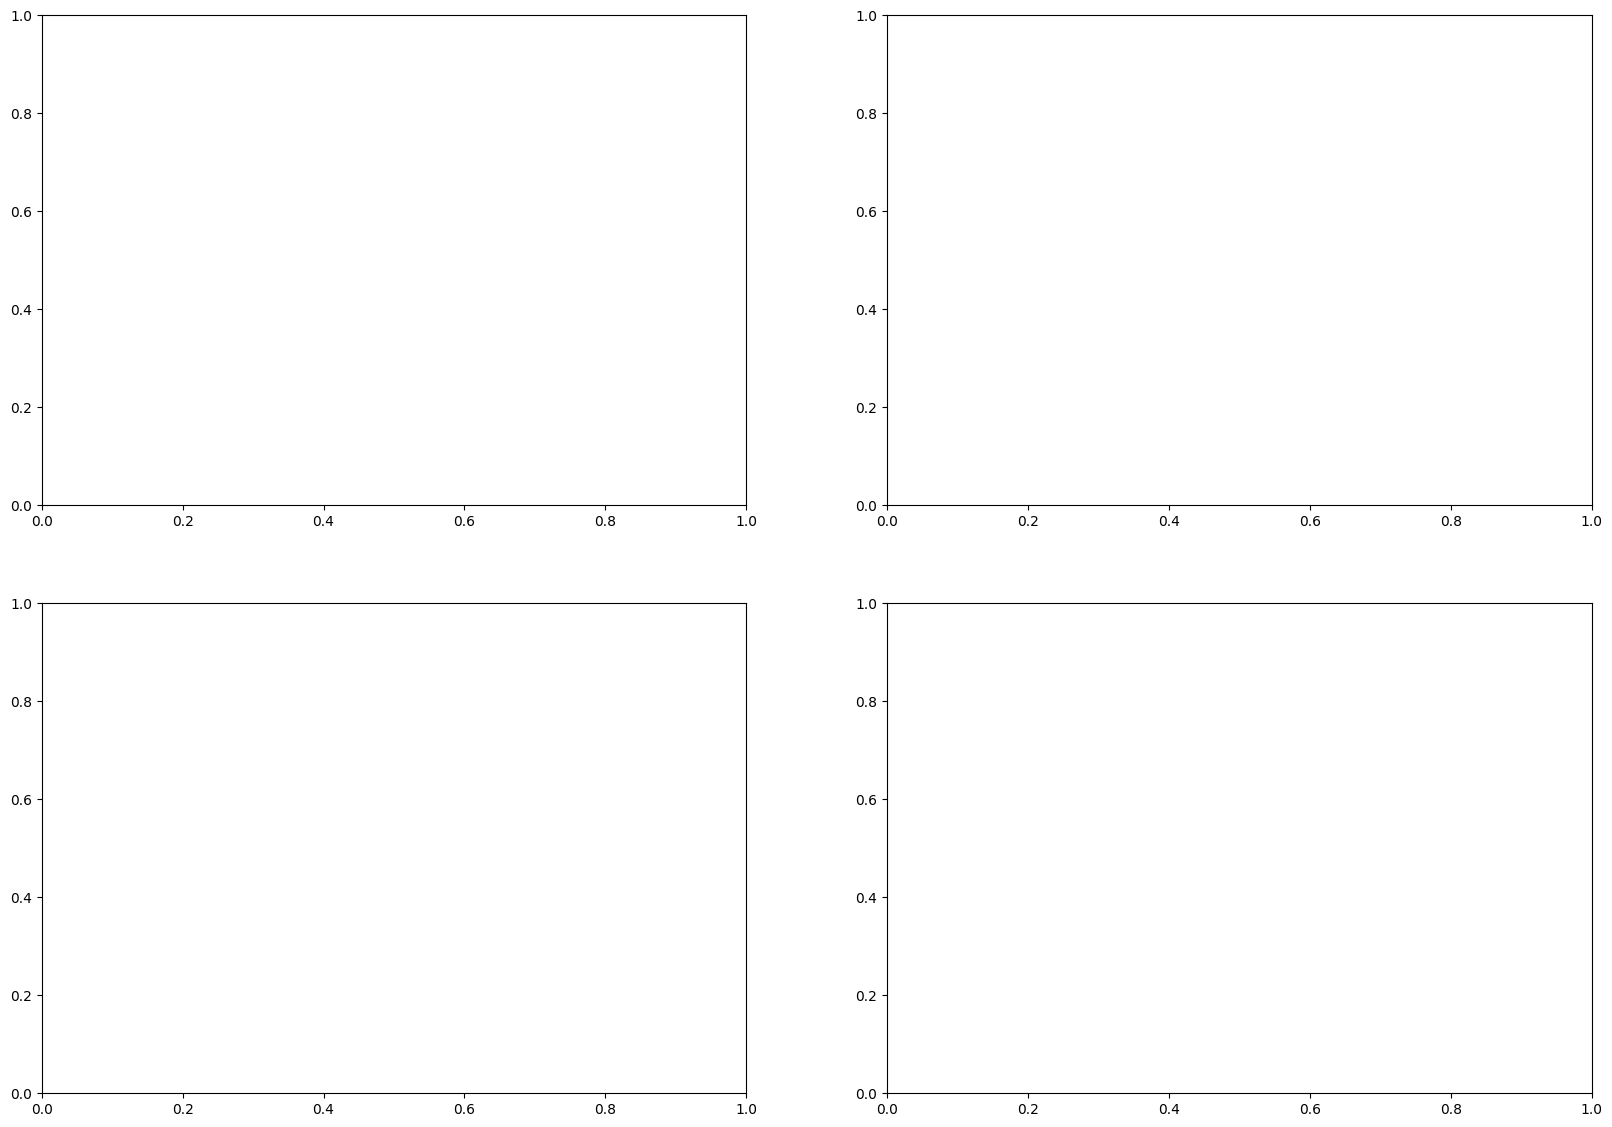

In [9]:
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white'})
RED, GREEN = '#e74c3c', '#2ecc71'

df_eda = df.copy()
df_eda['genre_list'] = df_eda['genres'].fillna('').astype(str).apply(lambda x: [g.strip() for g in x.split(',') if g.strip()])
df_genre = df_eda.explode('genre_list')
df_genre = df_genre[df_genre['genre_list'] != '']

df_eda['studio_list'] = df_eda['studios'].fillna('Unknown').astype(str).apply(lambda x: [s.strip() for s in x.split(',') if s.strip()])
df_studio = df_eda.explode('studio_list')
df_studio = df_studio[df_studio['studio_list'] != 'Unknown']

fig_eda, axes_eda = plt.subplots(2, 2, figsize=(20, 14))

top_15_genres = df_genre['genre_list'].value_counts().nlargest(15).index
g_data = df_genre[df_genre['genre_list'].isin(top_15_genres)]
g_cross = pd.crosstab(g_data['genre_list'], g_data['recommended'], normalize='index').loc[top_15_genres]
g_cross.plot(kind='barh', stacked=True, color=[RED, GREEN], ax=axes_eda[0, 0], width=0.8)
axes_eda[0, 0].set_title('Top 15 Genre by Recommendation Proportion', fontweight='bold')
axes_eda[0, 0].invert_yaxis()

top_10_studios = df_studio['studio_list'].value_counts().nlargest(10).index
s_data = df_studio[df_studio['studio_list'].isin(top_10_studios)]
s_cross = pd.crosstab(s_data['studio_list'], s_data['recommended'], normalize='index').loc[top_10_studios]
s_cross.plot(kind='barh', stacked=True, color=[RED, GREEN], ax=axes_eda[0, 1], width=0.8)
axes_eda[0, 1].set_title('Top 10 Studios by Recommendation Proportion', fontweight='bold')
axes_eda[0, 1].invert_yaxis()

top_10_g_box = df_genre['genre_list'].value_counts().nlargest(10).index
b_data = df_genre[df_genre['genre_list'].isin(top_10_g_box)]
sns.boxplot(x='genre_list', y='score', data=b_data, order=top_10_g_box, palette='Set2', ax=axes_eda[1, 0])
axes_eda[1, 0].axhline(q3_threshold, color='red', linestyle='--', label=f'Q3 ({q3_threshold:.2f})')
axes_eda[1, 0].set_title('Score Distribution per Top 10 Genre', fontweight='bold')
axes_eda[1, 0].tick_params(axis='x', rotation=45)

sns.histplot(df['episodes'], bins=50, log_scale=True, ax=axes_eda[1, 1], color='darkorange')
axes_eda[1, 1].set_title('Episode Distribution (Log Scale)', fontweight='bold')

plt.tight_layout()
plt.show()

## Langkah 3: Rekayasa Fitur (Pipeline Terintegrasi)
Membangun kelas khusus untuk MultiLabelBinarizer dan Target Encoding agar bisa dimasukkan ke dalam Pipeline Scikit-Learn.

In [ ]:
class GenreBinarizer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.mlb = MultiLabelBinarizer()
    def fit(self, X, y=None):
        genres_list = X.iloc[:, 0].fillna('').astype(str).apply(lambda x: [g.strip() for g in x.split(',') if g.strip()])
        self.mlb.fit(genres_list)
        return self
    def transform(self, X, y=None):
        genres_list = X.iloc[:, 0].fillna('').astype(str).apply(lambda x: [g.strip() for g in x.split(',') if g.strip()])
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            return self.mlb.transform(genres_list)
    def get_feature_names_out(self, input_features=None):
        return self.mlb.classes_

class StudioTargetEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, min_freq=5, smoothing=10):
        self.min_freq = min_freq; self.smoothing = smoothing
        self.mapping_ = {}; self.global_mean_ = 0
    def fit(self, X, y):
        s_series = X.iloc[:, 0].fillna('Unknown').astype(str).apply(lambda x: [s.strip() for s in x.split(',') if s.strip()])
        df_exp = pd.DataFrame({'studio': s_series, 'target': y}).explode('studio')
        counts = df_exp['studio'].value_counts()
        valid = counts[counts >= self.min_freq].index
        df_exp['studio_grouped'] = df_exp['studio'].where(df_exp['studio'].isin(valid), 'Other')
        self.global_mean_ = df_exp['target'].mean()
        stats = df_exp.groupby('studio_grouped')['target'].agg(['count', 'mean'])
        self.mapping_ = ((stats['count'] * stats['mean'] + self.smoothing * self.global_mean_) / (stats['count'] + self.smoothing)).to_dict()
        return self
    def transform(self, X, y=None):
        s_series = X.iloc[:, 0].fillna('Unknown').astype(str).apply(lambda x: [s.strip() for s in x.split(',') if s.strip()])
        def encode(studios):
            if not studios: return self.global_mean_
            return np.mean([self.mapping_.get(s, self.mapping_.get('Other', self.global_mean_)) for s in studios])
        return s_series.apply(encode).values.reshape(-1, 1)
    def get_feature_names_out(self, input_features=None):
        return np.array(['studio_encoded'])

preprocessor = ColumnTransformer(
    transformers=[
        ('genres', GenreBinarizer(), ['genres']),
        ('studios', StudioTargetEncoder(), ['studios']),
        ('type', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['type']),
        ('eps', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), ['episodes'])
    ], remainder='drop'
)

## Langkah 4: Hyperparameter Tuning
Mencari parameter ElasticNet terbaik menggunakan GridSearchCV.

In [ ]:
full_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(penalty='elasticnet', solver='saga', class_weight='balanced', max_iter=2000, random_state=42))
])

param_grid = {
    'classifier__C': [0.01, 0.1, 1.0, 10.0],
    'classifier__l1_ratio': [0.1, 0.5, 0.9]
}

grid = GridSearchCV(full_pipe, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
model = best_model.named_steps['classifier']
prep = best_model.named_steps['preprocessor']

print(f'Parameter Terbaik: {grid.best_params_}')
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

## Langkah 5: Optimasi Threshold
Mencari ambang batas keputusan probabilitas optimal untuk memaksimalkan metrik F1-Score.

In [ ]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)
numerator = 2 * (precisions[:-1] * recalls[:-1])
denominator = (precisions[:-1] + recalls[:-1])
f1_scores = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator!=0)

best_idx = np.argmax(f1_scores)
opt_thresh = thresholds[best_idx]
print(f'Optimal Decision Threshold (F1): {opt_thresh:.4f}')

y_pred_opt = (y_proba >= opt_thresh).astype(int)

## Langkah 6: Visualisasi Evaluasi Model
Membuat grid grafik untuk presentasi hasil klasifikasi pada test set.

In [ ]:
fig_eval, axes_eval = plt.subplots(2, 2, figsize=(16, 12))
BLUE = '#3498db'

clean_names = [n.split('__')[-1] for n in prep.get_feature_names_out()]
coef_df = pd.DataFrame({'Feature': clean_names, 'Coef': model.coef_[0]}).sort_values(by='Coef', key=abs, ascending=False).head(10)
colors_c = [GREEN if v >= 0 else RED for v in coef_df['Coef'].values]
axes_eval[0, 0].barh(coef_df['Feature'][::-1], coef_df['Coef'][::-1], color=colors_c[::-1], edgecolor='white')
axes_eval[0, 0].set_title('Top 10 Feature Importance (Log-Odds)')
axes_eval[0, 0].axvline(0, color='gray', linestyle='--')

sns.heatmap(confusion_matrix(y_test, y_pred_opt), annot=True, fmt='d', cmap='Blues', ax=axes_eval[0, 1])
axes_eval[0, 1].set_title(f'Confusion Matrix (Threshold {opt_thresh:.2f})')

fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)
axes_eval[1, 0].plot(fpr, tpr, color=BLUE, lw=2.5, label=f'AUC = {auc:.3f}')
axes_eval[1, 0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes_eval[1, 0].fill_between(fpr, tpr, alpha=0.08, color=BLUE)
axes_eval[1, 0].set_title('ROC Curve')
axes_eval[1, 0].legend(loc='lower right')

axes_eval[1, 1].plot(thresholds, precisions[:-1], 'b--', label='Precision')
axes_eval[1, 1].plot(thresholds, recalls[:-1], 'g-', label='Recall')
axes_eval[1, 1].plot(thresholds, f1_scores, 'r-', lw=2, label='F1-Score')
axes_eval[1, 1].axvline(opt_thresh, color='k', linestyle=':', label=f'Optimal ({opt_thresh:.2f})')
axes_eval[1, 1].set_title('Precision-Recall vs Threshold')
axes_eval[1, 1].legend(loc='lower left')

plt.tight_layout()
plt.show()

## Langkah 7: Inferensi
Menguji model klasifikasi dengan data yang benar-benar baru.

In [ ]:
def prediksi_anime(genres_str, studios_str, anime_type, episodes):
    input_df = pd.DataFrame({'genres': [genres_str], 'studios': [studios_str], 'type': [anime_type], 'episodes': [episodes]})
    proba = best_model.predict_proba(input_df)[0][1]
    label = '✅ RECOMMENDED' if proba >= opt_thresh else '❌ NOT RECOMMENDED'
    print(f'Genre: {genres_str:<35} Studio: {studios_str:<25} Type: {anime_type:<6} Eps: {episodes}')
    print(f'Hasil: {label}  |  Probabilitas: {proba*100:.1f}%\n')

prediksi_anime('Action, Sci-Fi', 'MAPPA', 'TV', 24)
prediksi_anime('Drama, Romance', 'Kyoto Animation', 'Movie', 1)
prediksi_anime('Adventure, Fantasy', 'Studio Ghibli', 'Movie', 1)

## Langkah 8: Ekspor Model
Menyimpan model ke dalam file .joblib untuk integrasi dengan Streamlit.

In [ ]:
joblib.dump(best_model, 'anime_recommendation_model.joblib')
print('Model berhasil disimpan sebagai anime_recommendation_model.joblib')

## Dokumentasi Demo Website (Streamlit)
Kamu bisa menggunakan model statis yang diekspor di atas untuk membuat antarmuka web.
Buat file dengan nama `app.py` pada komputer lokal, salin kode di bawah ini, lalu jalankan perintah terminal: `streamlit run app.py`

```python
import streamlit as st
import pandas as pd
import numpy as np
import joblib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import MultiLabelBinarizer

# Definisi kelas tetap wajib ada agar model bisa di-load
class GenreBinarizer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.mlb = MultiLabelBinarizer()
    def fit(self, X, y=None):
        return self
    def transform(self, X, y=None):
        genres_list = X.iloc[:, 0].fillna('').astype(str).apply(lambda x: [g.strip() for g in x.split(',') if g.strip()])
        return self.mlb.transform(genres_list)

class StudioTargetEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, min_freq=5, smoothing=10):
        self.min_freq = min_freq; self.smoothing = smoothing
        self.mapping_ = {}; self.global_mean_ = 0
    def fit(self, X, y):
        return self
    def transform(self, X, y=None):
        s_series = X.iloc[:, 0].fillna('Unknown').astype(str).apply(lambda x: [s.strip() for s in x.split(',') if s.strip()])
        def encode(studios):
            if not studios: return self.global_mean_
            return np.mean([self.mapping_.get(s, self.mapping_.get('Other', self.global_mean_)) for s in studios])
        return s_series.apply(encode).values.reshape(-1, 1)

st.set_page_config(page_title='Anime Predictor', page_icon='🎬', layout='centered')
st.title('🎬 Prediksi Rekomendasi Anime')
st.write('Masukkan detail anime untuk melihat probabilitas masuk Top 25% (Recommended).')

@st.cache_resource
def load_model():
    return joblib.load('anime_recommendation_model.joblib')

try:
    model = load_model()
except Exception as e:
    st.error(f'Gagal memuat model: {e}')
    st.stop()

GENRES = ['Action', 'Adventure', 'Comedy', 'Drama', 'Sci-Fi', 'Fantasy', 'Slice of Life', 'Romance', 'Supernatural', 'Mystery', 'Sports', 'Thriller', 'Horror']
STUDIOS = ['Madhouse', 'MAPPA', 'Kyoto Animation', 'Bones', 'Studio Ghibli', 'Wit Studio', 'ufotable', 'Sunrise', 'Toei Animation', 'J.C.Staff', 'Other']
TYPES = ['TV', 'Movie', 'OVA', 'ONA', 'Special']

with st.form('prediction_form'):
    selected_genres = st.multiselect('Pilih Genre', GENRES, default=['Action'])
    selected_studios = st.selectbox('Pilih Studio Utama', STUDIOS)
    
    col1, col2 = st.columns(2)
    with col1:
        anime_type = st.selectbox('Tipe Rilis', TYPES)
    with col2:
        episodes = st.number_input('Jumlah Episode', min_value=1, max_value=2000, value=12)
        
    submit_button = st.form_submit_button('Prediksi Sekarang')

if submit_button:
    if not selected_genres:
        st.warning('Pilih minimal satu genre!')
    else:
        input_data = pd.DataFrame({
            'genres': [", ".join(selected_genres)],
            'studios': [selected_studios],
            'type': [anime_type],
            'episodes': [episodes]
        })
        
        proba = model.predict_proba(input_data)[0][1]
        optimal_threshold = 0.45
        
        st.divider()
        col_res1, col_res2 = st.columns(2)
        with col_res1:
            st.metric('Probabilitas Sukses', f'{proba * 100:.1f}%')
        with col_res2:
            if proba >= optimal_threshold:
                st.success('✅ RECOMMENDED')
            else:
                st.error('❌ NOT RECOMMENDED')
```
